# Chapitre 4 - Cours 2 : Suivi d'instructions, coût et latence

Ce notebook couvre la seconde moitié de la section *Evaluation Criteria* : la capacité à
**suivre des instructions** et le couple **coût / latence**. Plan :

1. distinguer capacité métier et suivi d'instructions (section *Instruction-Following Capability*) ;
2. des contraintes vérifiables par programme, à la IFEval (section *Instruction-following criteria*) ;
3. un banc d'essai maison : Qwen 0.5B contre Qwen 1.5B ;
4. au-delà du format : listes de critères oui/non à la INFOBench ;
5. le jeu de rôle (section *Roleplaying*) ;
6. l'anatomie de la latence : TTFT, TPOT, débit (section *Cost and Latency*) ;
7. ce qui fait varier la latence : longueur du prompt, taille de lot, percentiles ;
8. du débit au coût, et une grille de critères avec exigences dures.

Toutes les mesures de latence sont faites **pour de vrai** sur le GPU de la machine
(RTX 5070 Laptop, 8 Go). Ce GPU est partagé avec d'autres processus : les valeurs absolues
peuvent varier d'une exécution à l'autre, mais les tendances sont robustes.

In [1]:
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")  # modèles déjà en cache : pas d'appel réseau
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from aie.plotting import (set_style, COLORS, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY,
                          GREEN, LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch04_systemes as c4

set_style()
pd.set_option("display.max_colwidth", 90)
llm.seed_everything(0)

## 1. Savoir faire ou savoir obéir ? (section *Instruction-Following Capability*)

**Le problème.** On demande à un modèle d'étiqueter le sentiment de messages par POSITIF,
NEGATIF ou NEUTRE. Il comprend le sentiment, mais répond « Le sentiment est plutôt
joyeux ! ». La **capacité métier** est là, le **suivi d'instructions** non, et l'application
en aval, qui attend exactement une des trois étiquettes, casse. Le suivi d'instructions
est essentiel pour toute sortie structurée (JSON, expression régulière), mais va au-delà :
« n'utilise que des mots de quatre lettres au plus » (l'exemple d'Ello, qui génère des
histoires avec le vocabulaire d'un enfant) n'est pas structuré, mais reste une contrainte.

Mesurons les deux séparément sur Qwen 0.5B : (a) la **conformité** (la sortie est-elle
exactement une étiquette ?) et (b) l'**exactitude** après une analyse tolérante (on cherche
l'étiquette n'importe où dans la réponse).

In [2]:
messages = [
    ("Je viens de recevoir ma commande, tout est parfait, merci !", "POSITIF"),
    ("Le colis est arrivé cassé et personne ne répond au téléphone.", "NEGATIF"),
    ("La réunion est déplacée à jeudi 14 h.", "NEUTRE"),
    ("Franchement, le meilleur restaurant du quartier.", "POSITIF"),
    ("Encore une panne de réseau, c'est insupportable.", "NEGATIF"),
    ("Le magasin ouvre à 9 heures le samedi.", "NEUTRE"),
    ("Service rapide et personnel adorable.", "POSITIF"),
    ("Je regrette vraiment cet achat, quelle déception.", "NEGATIF"),
    ("Le train de 8 h 12 part du quai 3.", "NEUTRE"),
    ("Une application claire et agréable à utiliser.", "POSITIF"),
]
consigne = "Quel est le sentiment de ce message ? Réponds par POSITIF, NEGATIF ou NEUTRE.\nMessage : "
outs = c4.chat_batch([consigne + m for m, _ in messages], llm.SMALL, max_new_tokens=30)

def tolerant(o):
    o_up = o.upper().replace("NÉGATIF", "NEGATIF")
    found = [l for l in ["POSITIF", "NEGATIF", "NEUTRE"] if l in o_up]
    return found[0] if len(found) == 1 else None

sent = pd.DataFrame(dict(message=[m for m, _ in messages], attendu=[g for _, g in messages], sortie=outs))
sent["conforme"] = sent.sortie.str.strip().str.strip(".").isin(["POSITIF", "NEGATIF", "NEUTRE"])
sent["exact (tolérant)"] = [tolerant(o) == g for o, g in zip(sent.sortie, sent.attendu)]
print(f"conformité stricte : {sent.conforme.mean():.0%}   exactitude tolérante : {sent['exact (tolérant)'].mean():.0%}")
print("étiquettes produites :", sent.sortie.str.strip().value_counts().to_dict())
sent[["message", "attendu", "sortie", "conforme"]]

conformité stricte : 100%   exactitude tolérante : 40%
étiquettes produites : {'POSITIF': 10}


,message,attendu,sortie,conforme
0,"Je viens de recevoir ma commande, tout est parfait, merci !",POSITIF,POSITIF,True
1,Le colis est arrivé cassé et personne ne répond au téléphone.,NEGATIF,POSITIF,True
2,La réunion est déplacée à jeudi 14 h.,NEUTRE,POSITIF,True
3,"Franchement, le meilleur restaurant du quartier.",POSITIF,POSITIF,True
4,"Encore une panne de réseau, c'est insupportable.",NEGATIF,POSITIF,True
5,Le magasin ouvre à 9 heures le samedi.,NEUTRE,POSITIF,True
6,Service rapide et personnel adorable.,POSITIF,POSITIF,True
7,"Je regrette vraiment cet achat, quelle déception.",NEGATIF,POSITIF,True
8,Le train de 8 h 12 part du quai 3.,NEUTRE,POSITIF,True
9,Une application claire et agréable à utiliser.,POSITIF,POSITIF,True


Les deux nombres racontent deux histoires différentes, et les deux échecs existent :

- **conformité faible, exactitude tolérante bonne** : le modèle « sait » mais n'obéit pas au
  format ; le remède est du côté du prompt, du décodage contraint (chapitre 2) ou du
  post-traitement, pas forcément d'un modèle plus gros ;
- **conformité parfaite, exactitude faible** : le modèle obéit au format mais répond mal.
  C'est ce qui arrive ici (relire le tableau) : Qwen 0.5B répond presque toujours la même
  étiquette, la première citée dans la consigne. Une métrique de format seule afficherait
  100 % et masquerait un classifieur inutile. Le livre souligne la difficulté symétrique : si un modèle échoue à
écrire un poème *lục bát*, est-ce parce qu'il ne connaît pas cette forme, ou parce qu'il n'a
pas compris la consigne ? Et une mauvaise performance peut venir d'une **mauvaise
instruction** autant que d'un mauvais modèle.

> **À retenir.** Mesurez séparément la capacité métier (exactitude avec une analyse
> tolérante) et le suivi d'instructions (conformité stricte au format). Les deux échecs
> n'appellent pas les mêmes remèdes.

## 2. Des contraintes vérifiables par programme (section *Instruction-following criteria*)

**L'idée d'IFEval** (Zhou et al., 2023, Google) : ne retenir que des instructions dont le
respect se **vérifie par un programme**, sans juge humain ni IA. « Utilise le mot
éphémère » se vérifie par une recherche de chaîne ; « au plus 50 mots » par un comptage.
IFEval en définit 25 types, répartis en groupes (mots-clés, langue, longueur, contenu
détectable, format détectable). Le module du chapitre en implémente 19, avec leur texte en
français et leur vérificateur :

In [3]:
types = pd.DataFrame([(c4.INSTRUCTION_GROUPS[k], k, txt) for k, (txt, _) in c4.INSTRUCTION_TYPES.items()],
                     columns=["groupe", "type", "consigne (gabarit)"]).sort_values(["groupe", "type"])
types.reset_index(drop=True)

,groupe,type,consigne (gabarit)
0,casse,majuscules,Toute ta réponse doit être écrite EN MAJUSCULES.
1,casse,minuscules,"Toute ta réponse doit être écrite en minuscules, sans aucune majuscule."
2,contenu,emplacements,"Ta réponse doit contenir au moins {n} emplacements entre crochets, comme [adresse]."
3,contenu,fin_phrase,Termine ta réponse exactement par la phrase « {phrase} ».
4,contenu,post_scriptum,"À la fin de ta réponse, ajoute un post-scriptum commençant par {marker}"
5,format,choix_parmi,Réponds uniquement par l'une des options suivantes : {options}.
6,format,json,Toute ta réponse doit être au format JSON.
7,format,puces,"Ta réponse doit contenir exactement {n} puces markdown, comme : * un point."
8,format,surlignage,"Mets en valeur au moins {n} passages en markdown, comme *passage important*."
9,format,titre,"Ta réponse doit avoir un titre entre doubles chevrons, comme <<titre>>."


**Quatre scores.** Une tâche peut porter plusieurs contraintes. IFEval rapporte :

- le score **au niveau du prompt** : fraction des tâches dont *toutes* les contraintes sont
  respectées ;
- le score **au niveau de l'instruction** : fraction des contraintes respectées ;
- chacun en version **stricte** (la réponse brute) et **souple** (*loose*) : la contrainte est
  jugée respectée si l'une de 8 variantes de la réponse la satisfait (sans la première
  ligne, sans la dernière, sans les deux, avec ou sans astérisques markdown). La version
  souple pardonne le « Voici ma réponse : » initial ou la mise en gras parasite.

Si une tâche $t$ porte les contraintes $c_{t,1},\dots,c_{t,m_t}$ de verdicts $v_{t,j}\in\{0,1\}$ :
$$\text{prompt} = \frac{1}{T}\sum_t \prod_j v_{t,j}, \qquad
  \text{instruction} = \frac{\sum_t\sum_j v_{t,j}}{\sum_t m_t}.$$
Le score au niveau du prompt est toujours inférieur ou égal : il faut tout réussir.

In [4]:
demo = c4.IFTask("Liste trois fruits rouges.", [c4.Instruction("puces", dict(n=3)), c4.Instruction("minuscules")])
reponses = {
    "parfaite": "* fraise\n* framboise\n* cerise",
    "préambule": "Voici trois fruits :\n* fraise\n* framboise\n* cerise",
    "gras": "* **fraise**\n* framboise\n* cerise",
    "quatre puces": "* fraise\n* framboise\n* cerise\n* groseille",
}
print("Tâche :", demo.prompt)
pd.concat({k: c4.evaluate_ifeval([demo], [v]).set_index("type")[["strict", "souple"]] for k, v in reponses.items()}).unstack()

Tâche : Liste trois fruits rouges. Ta réponse doit contenir exactement 3 puces markdown, comme : * un point. Toute ta réponse doit être écrite en minuscules, sans aucune majuscule.


strict            souple           
type          puces minuscules  puces minuscules
parfaite       True       True   True       True
préambule      True      False   True       True
gras           True       True   True       True
quatre puces  False       True   True       True

La réponse avec préambule échoue en strict sur les minuscules (« Voici » a une majuscule)
mais passe en souple (on retire la première ligne). Les quatre puces échouent dans les deux
cas : c'est une vraie violation.

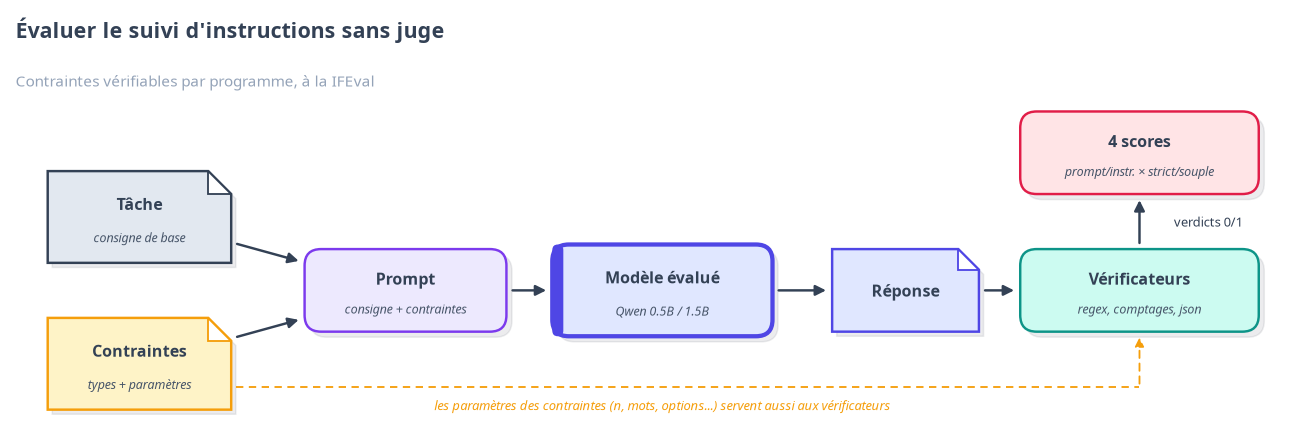

In [5]:
d = Diagram(14, 3.6, title="Évaluer le suivi d'instructions sans juge",
            subtitle="Contraintes vérifiables par programme, à la IFEval")
d.box("task", 1.4, 2.3, "Tâche", sub="consigne de base", color=SLATE, kind="doc", w=2.0, h=1.0)
d.box("cons", 1.4, 0.7, "Contraintes", sub="types + paramètres", color=AMBER, kind="doc", w=2.0, h=1.0)
d.box("prompt", 4.3, 1.5, "Prompt", sub="consigne + contraintes", color=VIOLET, w=2.2)
d.box("llm", 7.1, 1.5, "Modèle évalué", sub="Qwen 0.5B / 1.5B", color=INDIGO, kind="model", w=2.4, h=1.0)
d.box("resp", 9.75, 1.5, "Réponse", color=INDIGO, kind="doc", w=1.6, h=0.9)
d.box("chk", 12.3, 1.5, "Vérificateurs", sub="regex, comptages, json", color=TEAL, w=2.6)
d.box("score", 12.3, 3.0, "4 scores", sub="prompt/instr. × strict/souple", color=ROSE, w=2.6)
d.arrow("task", "prompt"); d.arrow("cons", "prompt")
d.arrow("prompt", "llm"); d.arrow("llm", "resp"); d.arrow("resp", "chk")
d.line([(2.45, 0.45), (12.3, 0.45), (12.3, 1.02)], color=AMBER, style="dashed")
d.note(7.1, 0.25, "les paramètres des contraintes (n, mots, options...) servent aussi aux vérificateurs", color=AMBER, fontsize=8.5)
d.arrow("chk", "score", "verdicts 0/1", label_offset=(0.75, 0))
d.show()

> **À retenir.** Une contrainte vérifiable par programme donne une évaluation exacte,
> reproductible et gratuite. IFEval rapporte quatre scores : prompt ou instruction, strict
> ou souple ; l'écart strict/souple mesure les « fautes de forme » pardonnables.

## 3. Un banc d'essai maison : Qwen 0.5B contre Qwen 1.5B

Le livre insiste : les benchmarks publics ne contiennent pas *vos* instructions ; il faut
construire le sien. Le module propose 24 tâches en français, portant 1 à 3 contraintes
chacune (34 contraintes). On génère de façon gloutonne (température 0) avec les deux modèles.

In [6]:
tasks = c4.IF_TASKS
prompts = [t.prompt for t in tasks]
gens = {"Qwen 0.5B": c4.chat_batch(prompts, llm.SMALL, max_new_tokens=220)}
llm.free_gpu()   # GPU partagé : un seul modèle en mémoire à la fois
gens["Qwen 1.5B"] = c4.chat_batch(prompts, llm.MEDIUM, max_new_tokens=220)
evals = {k: c4.evaluate_ifeval(tasks, v) for k, v in gens.items()}
scores = pd.DataFrame({k: c4.ifeval_summary(v) for k, v in evals.items()})
(scores * 100).round(1)

,Qwen 0.5B,Qwen 1.5B
prompt strict,29.2,50.0
prompt souple,29.2,54.2
instruction strict,43.8,62.5
instruction souple,43.8,65.6


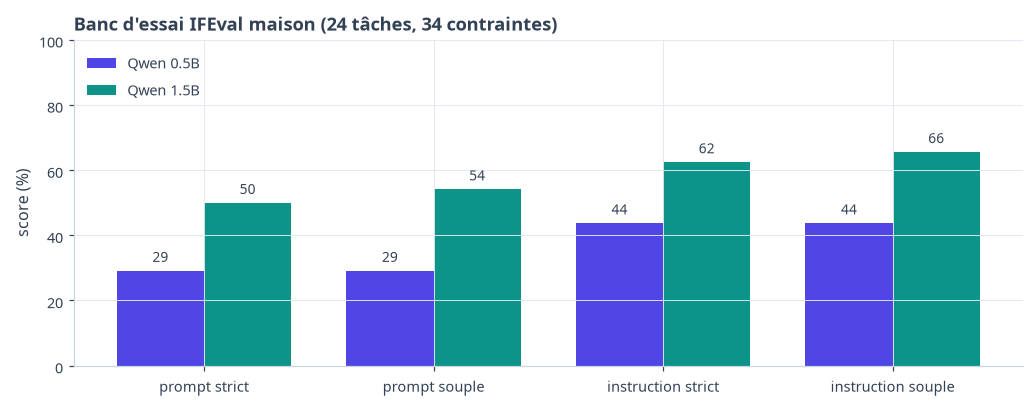

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
x = np.arange(len(scores))
for j, (col, c) in enumerate(zip(scores.columns, [INDIGO, TEAL])):
    ax.bar(x + (j - 0.5) * 0.38, scores[col] * 100, width=0.38, color=c, label=col)
annotate_bars(ax, "{:.0f}")
ax.set_xticks(x, scores.index); ax.set_ylabel("score (%)"); ax.set_ylim(0, 100)
ax.legend(loc="upper left"); ax.set_title("Banc d'essai IFEval maison (24 tâches, 34 contraintes)")
plt.tight_layout(); plt.show()

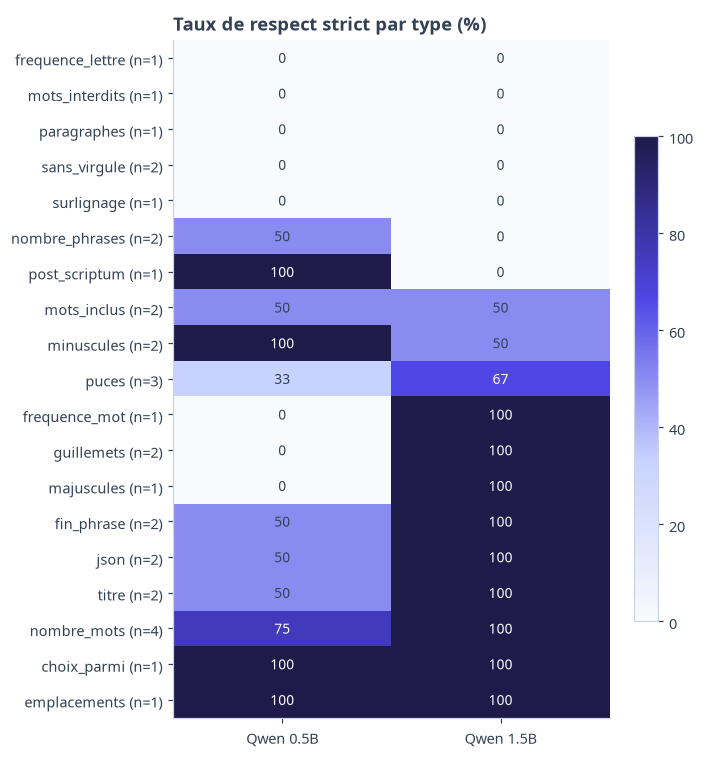

In [8]:
by_type = pd.DataFrame({k: v.groupby("type")["strict"].mean() for k, v in evals.items()})
by_type["n"] = evals["Qwen 0.5B"].groupby("type").size()
by_type = by_type.sort_values(["Qwen 1.5B", "Qwen 0.5B"])
fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(by_type[["Qwen 0.5B", "Qwen 1.5B"]].values * 100, cmap="aie_seq", vmin=0, vmax=100, aspect="auto")
ax.set_yticks(range(len(by_type)), [f"{t} (n={n})" for t, n in zip(by_type.index, by_type.n)])
ax.set_xticks([0, 1], ["Qwen 0.5B", "Qwen 1.5B"]); ax.grid(False)
for i in range(len(by_type)):
    for j, col in enumerate(["Qwen 0.5B", "Qwen 1.5B"]):
        v = by_type[col].iloc[i] * 100
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 60 else SLATE, fontsize=9)
ax.set_title("Taux de respect strict par type (%)")
plt.colorbar(im, ax=ax, fraction=0.05)
plt.tight_layout(); plt.show()

Quelques constats typiques des petits modèles (à relire sur la sortie ci-dessus, qui peut
légèrement varier) : les contraintes « naturelles » (JSON, emplacements entre crochets,
choix parmi des options) passent bien ; les contraintes qui vont **contre les habitudes de
génération** (ne pas utiliser de virgule, tout écrire en majuscules, éviter un mot
central du sujet comme « eau » pour parler d'un nuage, un nombre exact de puces) échouent
souvent. Chaque type n'a que 1 à 4 occurrences : les scores par type sont très bruités.
Regardons quelques échecs du petit modèle.

In [9]:
ev = evals["Qwen 0.5B"]
fails = ev[~ev.strict].drop_duplicates("tache").head(4)
for _, r in fails.iterrows():
    t = tasks[r.tache]
    print(f"[{r.type}] {t.prompt}\n  -> {gens['Qwen 0.5B'][r.tache][:160]!r}\n")

[nombre_mots] Décris les bienfaits du vélo en ville. Réponds en au plus 50 mots.
  -> "Le vélo en ville offre plusieurs avantages pour la santé et l'environnement :\n\n1. Économie de carburant : Le vélo est moins polluant que le véhicule automobile."

[puces] Donne des conseils pour bien dormir. Ta réponse doit contenir exactement 3 puces markdown, comme : * un point.
  -> "* **1.** Établissez une routine de sommeil régulière et précoce. Cela peut inclure la consommation d'alcool à moins que vous ne soyez en mesure de faire autreme"

[titre] Présente brièvement la ville de Lyon. Ta réponse doit avoir un titre entre doubles chevrons, comme <<titre>>. Réponds en au plus 3 phrases.
  -> "Lyon est une ville italienne située dans le sud-est de France, sur l'île de Provence. Elle est connue pour ses rues étroites, ses églises historiques et ses qua"

[mots_interdits] Explique ce qu'est un nuage. N'utilise aucun des mots suivants : « eau », « pluie ».
  -> "Un nuage est une forme céleste qui 

> **À retenir.** Un banc d'essai de suivi d'instructions se construit en quelques dizaines
> de lignes. Il révèle des faiblesses très spécifiques (contraintes « contre nature ») qui
> n'apparaissent pas dans un score global, et le modèle plus gros n'est pas meilleur partout.